In [8]:
# imports
from load_data import get_data
from descriptive_summary import DescriptiveSummary

# file path
FILENAME = "../../data/lung_cancer_dataset.csv"

# import data from file and print head to see if it worked
df = get_data(FILENAME)
print(df.head())

# create descriptive summary object
desc_summary = DescriptiveSummary(df)

  Patient_ID  Diagnosis_Year Diagnosis_Date       WHO_Region    Country  Age  \
0    LC-0001            2020     2020-11-04  Western Pacific      China   46   
1    LC-0002            2021     2021-12-09         Americas     Mexico   71   
2    LC-0003            2017     2017-04-05  Western Pacific      Japan   53   
3    LC-0004            2018     2018-11-24  Western Pacific  Singapore   55   
4    LC-0005            2024     2024-02-19  Western Pacific   Malaysia   54   

  Age_Group  Gender  Smoking_Status  Cigarettes_Per_Day  ...  Symptom_Count  \
0     40-49  Female  Current Smoker                  28  ...              5   
1     70-79    Male   Former Smoker                   5  ...              5   
2     50-59  Female    Never Smoked                   0  ...              3   
3     50-59    Male  Current Smoker                  21  ...              6   
4     50-59    Male    Never Smoked                   0  ...              5   

   Cancer_Type   NSCLC_Subtype Cancer_Stage 

In [ ]:
# describe the numerical values
print(df.describe())

       Diagnosis_Year          Age  Cigarettes_Per_Day  Years_Smoking  \
count     2000.000000  2000.000000         2000.000000    2000.000000   
mean      2021.262000    60.749000            7.274000       8.115500   
std          3.279746    10.337235           11.673734      12.682846   
min       2015.000000    30.000000            0.000000       0.000000   
25%       2019.000000    53.000000            0.000000       0.000000   
50%       2022.000000    60.000000            0.000000       0.000000   
75%       2024.000000    68.000000           14.000000      16.000000   
max       2026.000000    89.000000           56.000000      59.000000   

        Pack_Years          BMI  Risk_Factor_Count  Symptom_Count  \
count  2000.000000  2000.000000        2000.000000    2000.000000   
mean      8.931150    26.544500           1.709500       3.338000   
std      16.425992     4.045706           1.079672       1.620824   
min       0.000000    16.000000           0.000000       0.000000 

In [2]:
# Patient data frame and checks if the columns loaded correctly
patient_df = df.filter(items=["Gender", "Age_Group", "Country", "Family_History"])
print(patient_df.head(), "\n")

# tests to check each patient category 
print(desc_summary.get_category_count("Gender", patient_df),"\n")
print(desc_summary.get_category_count("Age_Group", patient_df),"\n")
print(desc_summary.get_category_count("Country", patient_df),"\n")
print(desc_summary.get_category_count("Family_History", patient_df),"\n")

   Gender Age_Group    Country Family_History
0  Female     40-49      China             No
1    Male     70-79     Mexico             No
2  Female     50-59      Japan             No
3    Male     50-59  Singapore            Yes
4    Male     50-59   Malaysia             No 

Gender
Male      1248
Female     752
Name: count, dtype: int64 

Age_Group
50-59    657
60-69    655
70-79    354
40-49    230
80-89     68
30-39     36
Name: count, dtype: int64 

Country
Japan           74
Malaysia        72
New Zealand     71
China           67
Philippines     62
Vietnam         62
Singapore       60
Australia       58
Mongolia        54
Sweden          52
South Korea     51
Germany         48
Russia          45
Cuba            42
Bangladesh      42
Brazil          42
Netherlands     42
Spain           41
Argentina       40
Italy           40
Colombia        37
France          36
Turkey          35
Poland          35
Canada          35
Peru            33
Maldives        33
Mexico          32
N

# Patient Descriptive Statistics Visuals
This section shows a pie chart showing the gender distribution of the patients, and a bar chart that shows the distribution of patients by their age group.

# Lung Cancer Patient Gender Distribution




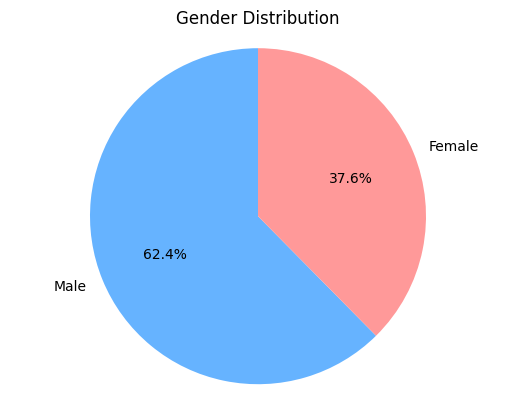

In [ ]:
# Pie Chart (Gender)
desc_summary.gender_pie_chart()

# Lung Cancer Patients by Age Group

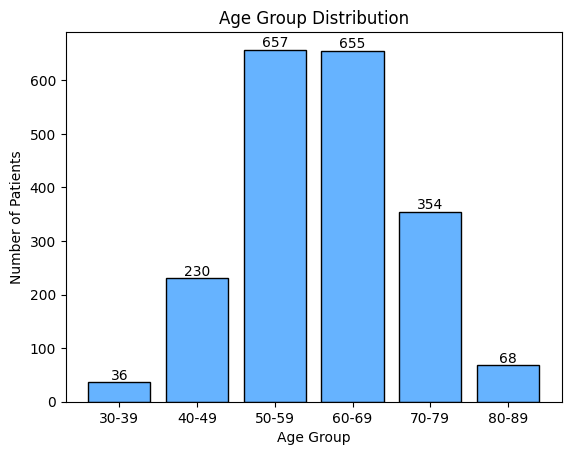

In [ ]:
# Bar Chart (Age Groups)
desc_summary.age_group_bar_chart()

# mean age, median age, mode age?

# Lifestyle Descriptive Summary


In [ ]:
# LIFESTYLE COUNTS
lifestyle_df = df.filter(items=["Smoking_Status", "Cigarettes_Per_Day", "Alcohol_Use", "Exercise_Frequency"])
print(lifestyle_df.head(),"\n")

smoker_count = lifestyle_df["Smoking_Status"].value_counts(dropna=True)
print(smoker_count, "\n")

current_smokers = lifestyle_df["Smoking_Status"] == "Current Smoker"
avg_cigs = lifestyle_df.groupby("Smoking_Status")["Cigarettes_Per_Day"].mean()
print(avg_cigs, "\n")

alcohol_count = lifestyle_df["Alcohol_Use"].value_counts(dropna=True)
print(alcohol_count, "\n")

exercise_count = lifestyle_df["Exercise_Frequency"].value_counts(dropna=True)
print(exercise_count, "\n")

# mean, median, mode for years of smoking?
# mean, median, mode BMI?
# mean, median, mode survival months?

   Smoking_Status  Cigarettes_Per_Day Alcohol_Use Exercise_Frequency
0  Current Smoker                  28  No Alcohol                Low
1   Former Smoker                   5       Heavy           Moderate
2    Never Smoked                   0    Moderate                Low
3  Current Smoker                  21  No Alcohol                Low
4    Never Smoked                   0  No Alcohol                Low 

Smoking_Status
Never Smoked      1311
Current Smoker     477
Former Smoker      212
Name: count, dtype: int64 

Smoking_Status
Current Smoker    23.698113
Former Smoker     15.301887
Never Smoked       0.000000
Name: Cigarettes_Per_Day, dtype: float64 

Alcohol_Use
Moderate      811
No Alcohol    786
Heavy         403
Name: count, dtype: int64 

Exercise_Frequency
Low         772
Moderate    719
High        509
Name: count, dtype: int64 



# Lifestyle Descriptive Statistics Visuals


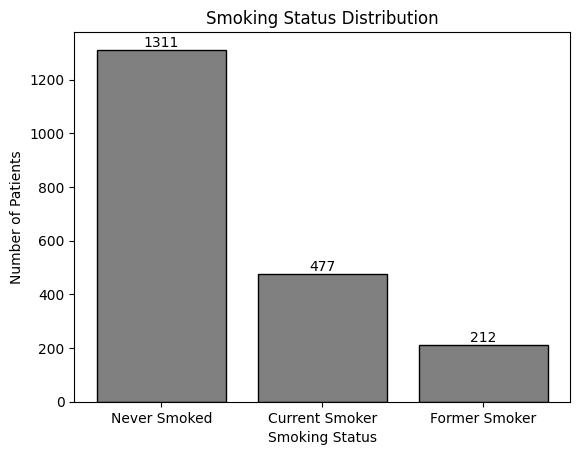

In [ ]:
# Bar Chart (Smoking Status)
desc_summary.smoking_status_bar_chart()

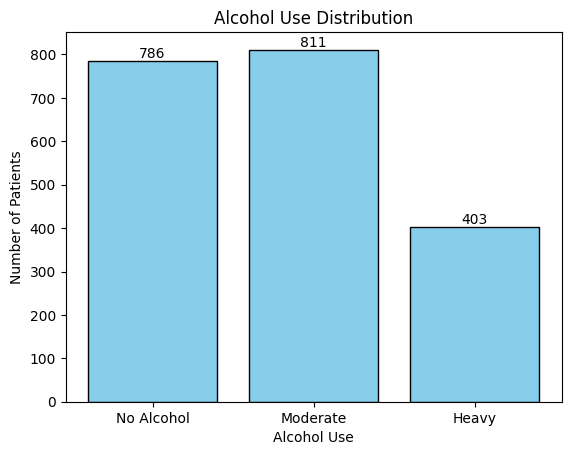

In [ ]:
# Bar Chart (Alcohol Use)
desc_summary.alcohol_use_bar_chart()

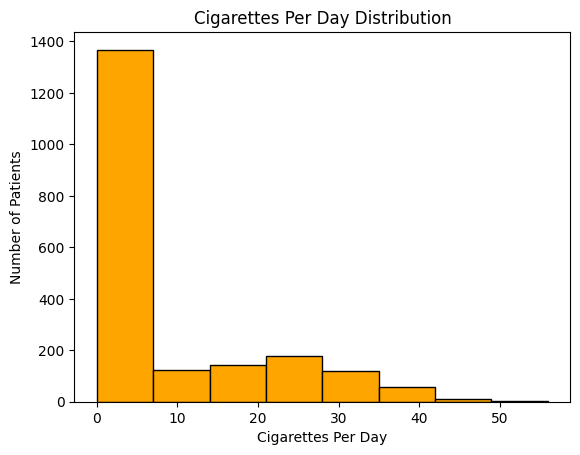

In [ ]:
# Cigarettes Per Day Histogram
desc_summary.cigs_per_day_hist()

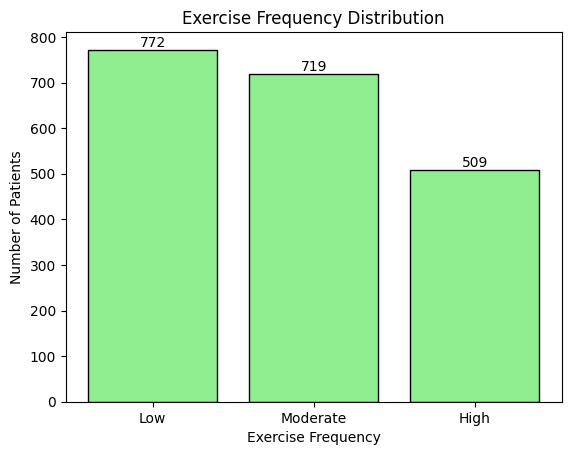

In [ ]:
# Exercise Frequency Bar Chart
desc_summary.exercise_freq_bar_chart()

# Environmental Descriptive Summary by Region

In [12]:
# ENVIRONMENTAL COUNTS 
environmental_df = df.filter(items=["WHO_Region", "Air_Pollution_Exposure", "Secondhand_Smoke"])
print(environmental_df.head(), "\n")

africa = df[df["WHO_Region"] == "Africa"]
africa_env = africa.filter(items=["WHO_Region", "Country", "Air_Pollution_Exposure"])
print(africa_env.head(), "\n")

americas = df[df["WHO_Region"] == "Americas"]
americas_env = americas.filter(items=["WHO_Region", "Country", "Air_Pollution_Exposure"])
print(americas_env.head(), "\n")

east_med = df[df["WHO_Region"] == "Eastern Mediterranean"]
east_med_env = east_med.filter(items=["WHO_Region", "Country", "Air_Pollution_Exposure"])
print(east_med_env.head(), "\n")

europe = df[df["WHO_Region"] == "Europe"]
europe_env = europe.filter(items=["WHO_Region", "Country", "Air_Pollution_Exposure"])
print(europe_env.head(), "\n")

sea = df[df["WHO_Region"] == "South-East Asia"]
sea_env = sea.filter(items=["WHO_Region", "Country", "Air_Pollution_Exposure"])
print(sea_env.head(), "\n")

west_pac = df[df["WHO_Region"] == "Western Pacific"]
west_pac_env = west_pac.filter(items=["WHO_Region", "Country", "Air_Pollution_Exposure"])
print(west_pac_env.head(), "\n")



        WHO_Region Air_Pollution_Exposure Secondhand_Smoke
0  Western Pacific               Moderate              Yes
1         Americas                   High              Yes
2  Western Pacific                   High              Yes
3  Western Pacific               Moderate               No
4  Western Pacific                   High               No 

   WHO_Region   Country Air_Pollution_Exposure
10     Africa   Nigeria                   High
50     Africa   Algeria               Moderate
62     Africa     Ghana                    Low
64     Africa  Ethiopia                   High
69     Africa   Morocco               Moderate 

   WHO_Region    Country Air_Pollution_Exposure
1    Americas     Mexico                   High
24   Americas  Argentina                    Low
26   Americas   Colombia                    Low
27   Americas  Argentina                   High
29   Americas     Brazil                    Low 

               WHO_Region  Country Air_Pollution_Exposure
5   Eastern 

# Environmental Descriptive Statistics Visual
For this section, we created a heatmap that shows the air pollution levels for each WHO region.


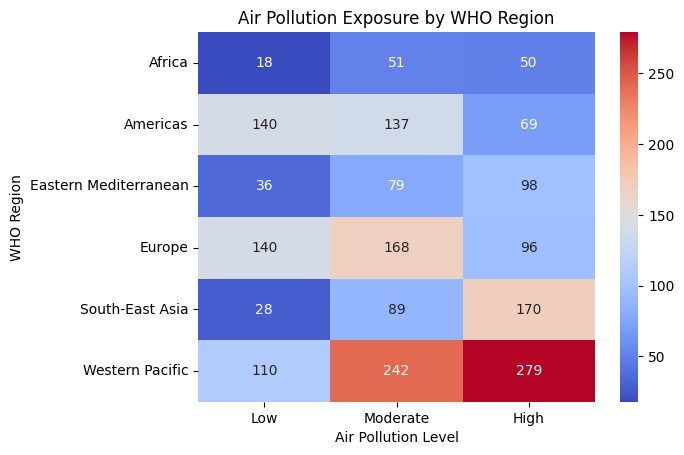

In [ ]:
# Air Pollution Heatmap
desc_summary.air_pollution_heatmap()

## High Air Pollution Level
We were curious which countries in the Western Pacific Regions have a high pollution level

In [25]:
# filter just western pacific region and high air pollution exposure
high_west_pac = west_pac[west_pac["Air_Pollution_Exposure"] == "High"]
high_west_filtered = high_west_pac.filter(items=["WHO_Region", "Country", "Air_Pollution_Exposure"])

print(high_west_filtered)

high_countries = high_west_filtered["Country"].unique()
print(high_countries)

           WHO_Region      Country Air_Pollution_Exposure
2     Western Pacific        Japan                   High
4     Western Pacific     Malaysia                   High
7     Western Pacific    Singapore                   High
40    Western Pacific    Australia                   High
43    Western Pacific     Malaysia                   High
...               ...          ...                    ...
1973  Western Pacific     Mongolia                   High
1979  Western Pacific    Singapore                   High
1980  Western Pacific  Philippines                   High
1987  Western Pacific        China                   High
1993  Western Pacific     Malaysia                   High

[279 rows x 3 columns]
['Japan' 'Malaysia' 'Singapore' 'Australia' 'South Korea' 'New Zealand'
 'Vietnam' 'Philippines' 'Mongolia' 'China']
